# Étape 3 – Reconstruction des rounds et correction de la fuite de données

## Le problème

Chaque ligne est une **photo** d'un round, prise environ toutes les 20 secondes. Un round donne donc plusieurs lignes **qui ont toutes le même gagnant**.

| Ligne | round (caché) | temps restant | joueurs CT / T | gagnant |
| --- | --- | --- | --- | --- |
| 1 | A | 175 s | 5 / 5 | CT |
| 2 | A | 155 s | 5 / 4 | CT |
| 3 | A | 135 s | 4 / 4 | CT |

L'ancien notebook mélangeait les lignes au hasard (`train_test_split`). La ligne 2 pouvait se retrouver dans le **test** et les lignes 1 et 3, presque identiques, dans le **train**. Le modèle n'avait alors pas besoin de « comprendre » le jeu : il lui suffisait de **reconnaître le round**. C'est une **fuite de données** (*data leakage*) et le score obtenu est trop optimiste.

## La solution

1. Retrouver à quel **round** et à quel **match** appartient chaque ligne (le dataset ne le donne pas).
2. Découper train/test **par match** : toutes les photos d'un match vont du même côté.
3. Mesurer de combien l'ancien score était surestimé.

## 0. Imports

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

from src.config import TARGET
from src.data import load_data
from src.rounds import (add_round_ids, build_processed_data, check_rounds, drop_impossible_rows,
                        print_round_report, score_based_winner)
from src.leakage import OLD_FEATURES, all_features, compare_splits
from src.viz import COLOR_CT, COLOR_T, COLOR_TEXT, COLOR_TEXT_MUTED, save_fig, set_style

set_style()

## 1. Reconstruire les rounds et les matchs

Les lignes sont rangées dans l'ordre chronologique. La fonction `add_round_ids` (dans `src/rounds.py`) utilise le score :

- **nouveau match** : la carte change, ou le score total (`ct_score + t_score`) diminue (retour à 0-0) ;
- **nouveau round** : nouveau match, ou le score total change.

Le score augmente de 1 à chaque fin de round, sans exception : **un round = un même score dans un même match**.

> **Première version abandonnée :** au départ, la règle utilisait aussi le gagnant (« nouveau round si le gagnant change ») et le chrono. Sur les vraies données, elle coupait 32 % des rounds en deux. L'enquête ci-dessous explique pourquoi.

In [2]:
raw = add_round_ids(drop_impossible_rows(load_data()))
print(f"{raw['match_id'].nunique():,} matchs et {raw['round_id'].nunique():,} rounds reconstruits")

[clean] 1 ligne(s) supprimée(s) : plus de 5 joueurs dans une équipe
701 matchs et 18,703 rounds reconstruits


## 2. Une erreur d'étiquette dans le dataset

On compte les rounds qui contiennent **deux gagnants différents** (impossible dans le jeu).

In [3]:
winners_per_round = raw.groupby("round_id")["round_winner"].nunique()
print(f"Rounds avec 2 gagnants : {(winners_per_round > 1).sum():,} sur {len(winners_per_round):,} "
      f"({(winners_per_round > 1).mean():.1%})")

# À quelle photo du round le gagnant change-t-il ?
prev = raw.groupby("round_id")["round_winner"].shift()
change = raw[prev.notna() & (raw["round_winner"].astype(str) != prev.astype(str))]
print("Position de la photo où le gagnant change :")
print(change["snapshot_idx"].value_counts().rename("nombre").to_string())

Rounds avec 2 gagnants : 6,763 sur 18,703 (36.2%)
Position de la photo où le gagnant change :
snapshot_idx
1    6763


Le gagnant change **toujours juste après la première photo** du round. Regardons un exemple.

In [4]:
cols = ["round_id", "snapshot_idx", "ct_score", "t_score", "time_left", "ct_money", "t_money",
        "ct_players_alive", "t_players_alive", "round_winner"]
example = winners_per_round[winners_per_round > 1].index[5]
raw.loc[raw["round_id"].between(example - 1, example + 1), cols]

,round_id,snapshot_idx,ct_score,t_score,time_left,ct_money,t_money,ct_players_alive,t_players_alive,round_winner
40,7,0,4.0,3.0,174.97,28550.0,32200.0,5.0,5.0,CT
41,7,1,4.0,3.0,114.97,5000.0,5450.0,5.0,5.0,T
42,7,2,4.0,3.0,94.97,350.0,5550.0,4.0,5.0,T
43,7,3,4.0,3.0,74.97,300.0,4950.0,3.0,4.0,T
44,7,4,4.0,3.0,27.35,300.0,3050.0,2.0,3.0,T
45,7,5,4.0,3.0,7.35,250.0,3350.0,1.0,3.0,T
46,8,0,4.0,4.0,174.96,12400.0,23100.0,5.0,5.0,T
47,8,1,4.0,4.0,114.96,500.0,10500.0,5.0,5.0,CT
48,8,2,4.0,4.0,94.96,500.0,10500.0,5.0,5.0,CT
49,8,3,4.0,4.0,74.96,450.0,9150.0,4.0,4.0,CT


**Lecture :** la première photo de chaque round est prise pendant la **phase d'achat** (chrono vers 175 s, argent pas encore dépensé, score déjà mis à jour). Elle porte le gagnant du round **précédent**, alors que toutes les photos suivantes portent le vrai gagnant.

**Vérification indépendante :** le score du round suivant dit qui a gagné (si `t_score` augmente de 1, les T ont gagné). On compare ce « gagnant selon le score » avec l'étiquette de la première et de la dernière photo de chaque round.

In [5]:
sw = score_based_winner(raw)
known = sw.notna()
first = raw.groupby("round_id")["round_winner"].first().astype(str)
last = raw.groupby("round_id")["round_winner"].last().astype(str)
check = pd.Series({
    "1re photo du round": (first[known] == sw[known]).mean(),
    "dernière photo du round": (last[known] == sw[known]).mean(),
}, name="accord avec le score suivant")
print(f"Rounds dont le gagnant se déduit du score : {known.mean():.1%}")
check.to_frame().style.format("{:.1%}")

Rounds dont le gagnant se déduit du score : 92.8%


,accord avec le score suivant
1re photo du round,63.9%
dernière photo du round,99.2%


**Conclusion de l'enquête :** l'étiquette de la **dernière** photo est la bonne. La fonction `fix_labels` donne donc à toutes les photos d'un round le gagnant de sa dernière photo.

C'est un point important : les anciens modèles apprenaient en partie sur des étiquettes fausses.

## 3. Données finales de l'étape 3

`build_processed_data()` enchaîne tout : suppression des lignes impossibles, reconstruction des rounds, correction des étiquettes, découpage train/test, sauvegarde dans `data/processed/csgo_rounds.csv`.

In [6]:
df = build_processed_data()
report = check_rounds(df)
print_round_report(report)

[clean] 1 ligne(s) supprimée(s) : plus de 5 joueurs dans une équipe
[save] csgo_rounds.csv sauvegardé (122,409 lignes)

========== Reconstruction des rounds ==========
Lignes                            : 122,409
Matchs reconstruits               : 701
Rounds reconstruits               : 18,703
Rounds par match (médiane)        : 26
Photos par round (médiane / max)  : 6 / 74
Rounds de plus de 20 photos       : 40 (pauses : chrono bloqué)
Écart de score entre 2 rounds consécutifs d'un même match :
   +1 (normal)                    : 100.0%
   +2 ou plus (round sans photo)  : 0.0%
--- Étiquettes ---
Lignes dont le gagnant a été corrigé : 6,763 (5.5%)
Rounds avec 2 gagnants (doit = 0)    : 0
Gagnant vérifiable par le score      : 92.8% des rounds
Accord étiquette / score suivant     : 99.2%



**Comment lire ce rapport :**
- « Rounds avec 2 gagnants » doit valoir **0**.
- L'écart de score entre deux rounds consécutifs d'un même match doit valoir **+1**. Un écart de +2 voudrait dire qu'un round n'a aucune photo.
- « Accord étiquette / score suivant » mesure la qualité des étiquettes corrigées.
- Les rounds de plus de 20 photos sont des **pauses** (chrono bloqué, par exemple avant le début du match).

## 4. Vérification à l'œil : un round avec bombe posée

On vérifie que les photos se suivent logiquement : le temps diminue (sauf quand la bombe est posée : le chrono repart à 40 s), le score reste le même, le gagnant est unique.

In [7]:
cols = ["match_id", "round_id", "snapshot_idx", "map", "ct_score", "t_score", "time_left",
        "bomb_planted", "ct_players_alive", "t_players_alive", "round_winner", "label_fixed"]
planted_rounds = df.loc[df["bomb_planted"].astype(bool), "round_id"].unique()
example = planted_rounds[len(planted_rounds) // 2]
df.loc[df["round_id"].between(example - 1, example + 1), cols]

,match_id,round_id,snapshot_idx,map,ct_score,t_score,time_left,bomb_planted,ct_players_alive,t_players_alive,round_winner,label_fixed
60708,347,9353,0,de_inferno,2.0,8.0,166.95,False,5.0,5.0,CT,True
60709,347,9353,1,de_inferno,2.0,8.0,106.95,False,5.0,5.0,CT,False
60710,347,9353,2,de_inferno,2.0,8.0,86.95,False,5.0,4.0,CT,False
60711,347,9353,3,de_inferno,2.0,8.0,35.79,True,4.0,3.0,CT,False
60712,347,9353,4,de_inferno,2.0,8.0,15.79,True,2.0,0.0,CT,False
60713,347,9354,0,de_inferno,3.0,8.0,166.88,False,5.0,5.0,CT,False
60714,347,9354,1,de_inferno,3.0,8.0,106.88,False,5.0,5.0,CT,False
60715,347,9354,2,de_inferno,3.0,8.0,86.83,False,5.0,3.0,CT,False
60716,347,9354,3,de_inferno,3.0,8.0,66.83,False,4.0,2.0,CT,False
60717,347,9354,4,de_inferno,3.0,8.0,46.83,False,4.0,1.0,CT,False


## 5. Combien de photos par round ?

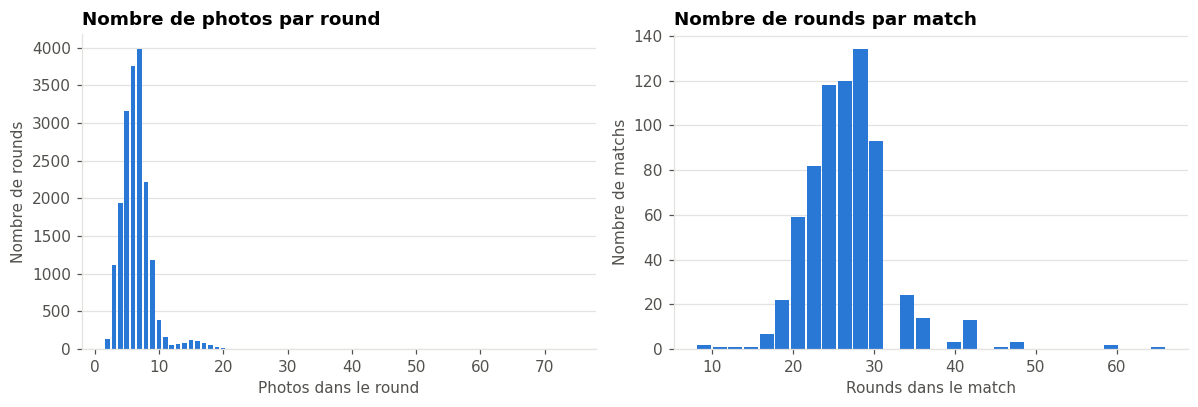

En moyenne, un round contient 6.5 photos : chaque round apparaît donc ~7 fois dans les données.


In [8]:
per_round = df.groupby("round_id").size()
per_match = df.groupby("match_id")["round_id"].nunique()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
vc = per_round.value_counts().sort_index()
axes[0].bar(vc.index, vc.values, color=COLOR_CT, width=0.7)
axes[0].set_title("Nombre de photos par round")
axes[0].set_xlabel("Photos dans le round")
axes[0].set_ylabel("Nombre de rounds")
axes[0].grid(axis="x", visible=False)

axes[1].hist(per_match, bins=30, color=COLOR_CT, rwidth=0.9)
axes[1].set_title("Nombre de rounds par match")
axes[1].set_xlabel("Rounds dans le match")
axes[1].set_ylabel("Nombre de matchs")
axes[1].grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

print(f"En moyenne, un round contient {per_round.mean():.1f} photos : "
      f"chaque round apparaît donc ~{per_round.mean():.0f} fois dans les données.")

## 6. Les doublons de l'étape 1 viennent-ils du même round ?

À l'étape 1, on a trouvé des lignes strictement identiques. Si ce sont des photos successives d'un même round (personne n'a bougé), c'est normal. Avec un découpage aléatoire, ces doublons sont la forme la plus directe de fuite : **la même ligne** peut être dans le train et dans le test.

In [9]:
feature_cols = all_features(df) + ["map"]
dup = df[df.duplicated(subset=feature_cols, keep=False)]
groups = dup.groupby(feature_cols, observed=True, dropna=False)["round_id"].nunique()
print(f"Lignes en double         : {len(dup):,}")
print(f"Groupes de doublons      : {len(groups):,}")
if len(groups):
    print(f"... dans un seul round   : {(groups == 1).mean():.1%}")
    print(f"... dans plusieurs rounds: {(groups > 1).mean():.1%} (souvent des débuts de round identiques : 5 contre 5, rien acheté)")

Lignes en double         : 7,061
Groupes de doublons      : 1,928
... dans un seul round   : 88.8%
... dans plusieurs rounds: 11.2% (souvent des débuts de round identiques : 5 contre 5, rien acheté)


## 7. L'expérience : mesurer la fuite

On entraîne **exactement le même modèle** (Random Forest à 100 arbres, comme l'ancien notebook) avec 3 découpages :

| Découpage | Ce qu'il fait |
| --- | --- |
| Aléatoire (ancien) | mélange les lignes, comme l'ancien notebook |
| Par round | toutes les photos d'un round sont du même côté |
| Par match | toutes les photos d'un match sont du même côté (le plus strict, le plus réaliste) |

On le fait avec deux jeux de variables : les 20 variables de l'ancien notebook, puis toutes les variables.

La colonne « rounds du test vus en train » donne la part des lignes de test dont le round est **aussi** présent dans le train : c'est la fuite, mesurée directement.

⏱️ Cette cellule prend **2 à 5 minutes** (6 modèles entraînés).

In [10]:
results = compare_splits(df, {
    "20 variables (ancien)": OLD_FEATURES,
    "Toutes les variables": all_features(df),
})
table = results[["variables", "découpage", "rounds du test vus en train",
                 "train_accuracy", "test_accuracy", "test_roc_auc"]]
table.style.format({"rounds du test vus en train": "{:.0%}", "train_accuracy": "{:.3f}",
                    "test_accuracy": "{:.3f}", "test_roc_auc": "{:.3f}"})

  20 variables (ancien)  | Aléatoire (ancien) | accuracy test 0.777 | AUC 0.864 | 7 s
  20 variables (ancien)  | Par round          | accuracy test 0.682 | AUC 0.766 | 5 s
  20 variables (ancien)  | Par match          | accuracy test 0.688 | AUC 0.772 | 6 s
  Toutes les variables   | Aléatoire (ancien) | accuracy test 0.826 | AUC 0.911 | 14 s
  Toutes les variables   | Par round          | accuracy test 0.703 | AUC 0.795 | 11 s
  Toutes les variables   | Par match          | accuracy test 0.698 | AUC 0.791 | 11 s


,variables,découpage,rounds du test vus en train,train_accuracy,test_accuracy,test_roc_auc
0,20 variables (ancien),Aléatoire (ancien),100%,0.963,0.777,0.864
1,20 variables (ancien),Par round,0%,0.963,0.682,0.766
2,20 variables (ancien),Par match,0%,0.963,0.688,0.772
3,Toutes les variables,Aléatoire (ancien),100%,0.995,0.826,0.911
4,Toutes les variables,Par round,0%,0.995,0.703,0.795
5,Toutes les variables,Par match,0%,0.995,0.698,0.791


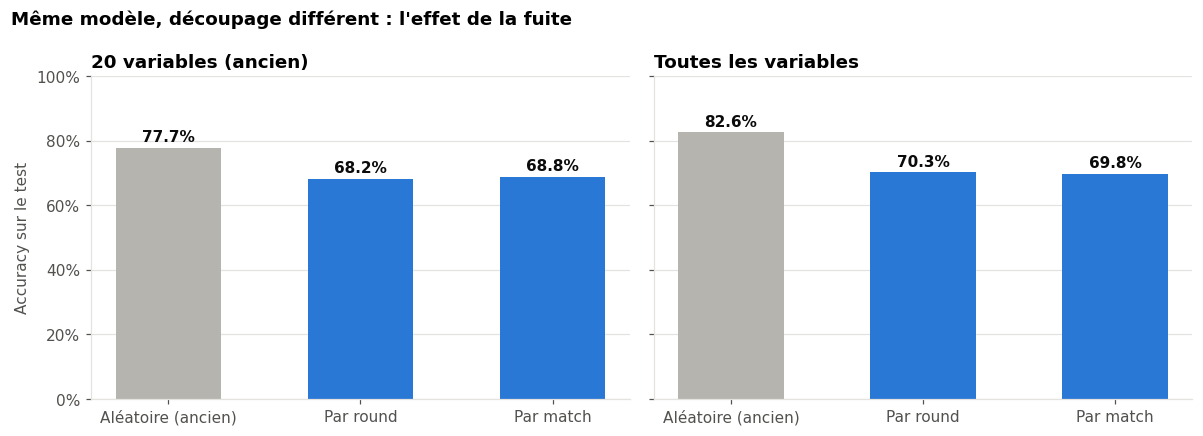

In [11]:
order = ["Aléatoire (ancien)", "Par round", "Par match"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, (fs, part) in zip(axes, results.groupby("variables", sort=False)):
    part = part.set_index("découpage").loc[order]
    colors = ["#b5b4ae", COLOR_CT, COLOR_CT]  # gris = score faussé par la fuite
    bars = ax.bar(order, part["test_accuracy"], color=colors, width=0.55)
    for bar, v in zip(bars, part["test_accuracy"]):
        ax.text(bar.get_x() + bar.get_width() / 2, v + 0.01, f"{v:.1%}", ha="center",
                va="bottom", fontsize=10, color=COLOR_TEXT, fontweight="bold")
    ax.set_title(fs)
    ax.set_ylim(0, 1)
    ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Accuracy sur le test")
fig.suptitle("Même modèle, découpage différent : l'effet de la fuite", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
save_fig(fig, "07_fuite_de_donnees")
plt.show()

**Lecture :** la barre grise est le score « à la manière de l'ancien notebook ». Les barres bleues sont les scores honnêtes. L'écart entre les deux est la part du score qui venait de la fuite.

## 8. Le découpage final, figé pour toute la suite

On choisit le découpage **par match** :
- c'est le plus réaliste : en vrai, on prédit des matchs que le modèle n'a jamais vus ;
- c'est le plus strict : les rounds d'un même match se ressemblent (mêmes équipes, même économie).

Le découpage est enregistré dans la colonne `split` du fichier `data/processed/csgo_rounds.csv`. **Le test ne sera plus jamais utilisé pour choisir un modèle** : seulement pour l'évaluation finale (étape 7). Pour comparer les modèles, on fera de la validation croisée par groupe (`GroupKFold`) à l'intérieur du train.

In [12]:
summary = df.groupby("split").agg(
    lignes=("round_id", "size"),
    rounds=("round_id", "nunique"),
    matchs=("match_id", "nunique"),
    victoires_T=(TARGET, "mean"),
).loc[["train", "test"]]
summary["part des lignes"] = summary["lignes"] / summary["lignes"].sum()

overlap = set(df.loc[df["split"] == "train", "match_id"]) & set(df.loc[df["split"] == "test", "match_id"])
print(f"Matchs présents à la fois dans le train et le test : {len(overlap)} (doit être 0)")
summary.style.format({"lignes": "{:,}", "rounds": "{:,}", "matchs": "{:,}",
                      "victoires_T": "{:.1%}", "part des lignes": "{:.1%}"})

Matchs présents à la fois dans le train et le test : 0 (doit être 0)


,lignes,rounds,matchs,victoires_T,part des lignes
split,,,,,
train,"97,431","14,935",560,51.1%,79.6%
test,"24,978","3,768",141,50.4%,20.4%


## 9. Résumé des résultats

Chiffres clés de la reconstruction des rounds et de l'expérience sur la fuite de données.

In [13]:
r = results.set_index(["variables", "découpage"])
print("=== Résumé de l'étape 3 ===")
print(f"Lignes après nettoyage   : {report['n_rows']:,}")
print(f"Matchs / rounds          : {report['n_matches']:,} / {report['n_rounds']:,}")
print(f"Rounds avec 2 gagnants   : {report['rounds_with_several_winners']}")
print(f"Étiquettes corrigées     : {report['n_labels_fixed']:,} lignes ({report['n_labels_fixed'] / report['n_rows']:.1%})")
print(f"Accord 1re / dernière photo avec le score : {check.iloc[0]:.1%} / {check.iloc[1]:.1%}")
print(f"Écart de score +1 / +2   : {report['share_score_step_1']:.1%} / {report['share_score_step_2plus']:.1%}")
print(f"Photos par round (moy.)  : {per_round.mean():.1f}")
for fs in ["20 variables (ancien)", "Toutes les variables"]:
    a, m = r.loc[(fs, "Aléatoire (ancien)")], r.loc[(fs, "Par match")]
    print(f"{fs:<22}: aléatoire {a['test_accuracy']:.1%} -> par match {m['test_accuracy']:.1%} "
          f"(écart {100 * (a['test_accuracy'] - m['test_accuracy']):.1f} points) | "
          f"AUC {a['test_roc_auc']:.3f} -> {m['test_roc_auc']:.3f}")
print("Train / test             :", ", ".join(f"{k} {v:,} lignes" for k, v in summary["lignes"].items()))

=== Résumé de l'étape 3 ===
Lignes après nettoyage   : 122,409
Matchs / rounds          : 701 / 18,703
Rounds avec 2 gagnants   : 0
Étiquettes corrigées     : 6,763 lignes (5.5%)
Accord 1re / dernière photo avec le score : 63.9% / 99.2%
Écart de score +1 / +2   : 100.0% / 0.0%
Photos par round (moy.)  : 6.5
20 variables (ancien) : aléatoire 77.7% -> par match 68.8% (écart 8.9 points) | AUC 0.864 -> 0.772
Toutes les variables  : aléatoire 82.6% -> par match 69.8% (écart 12.8 points) | AUC 0.911 -> 0.791
Train / test             : train 97,431 lignes, test 24,978 lignes


## 10. Conclusion de l'étape 3

**Reconstruction :** 701 matchs et 18 703 rounds (26 rounds par match en médiane, environ 6,5 photos par round). Entre deux rounds consécutifs d'un même match, le score augmente toujours de 1 : la reconstruction est cohérente.

**Erreur d'étiquette découverte :** la première photo de chaque round (phase d'achat) portait le gagnant du round précédent. 6 763 lignes (5,5 %) ont été corrigées. Après correction, l'étiquette correspond au gagnant déduit du score suivant dans 99,2 % des cas (contre 63,9 % pour la première photo avant correction).

**Fuite de données :** avec le même Random Forest et toutes les variables, l'accuracy passe de 82,6 % (découpage aléatoire) à 69,8 % (découpage par match), soit 12,8 points de score artificiel. Avec un découpage aléatoire, 93 % des lignes de test appartenaient à un round déjà vu à l'entraînement.

**Bilan :** le score de 83 % de l'ancien notebook était gonflé deux fois : par la fuite (photos d'un même round dans le train et le test), et par des étiquettes fausses mais faciles à deviner (l'équipe qui vient de gagner un round a plus d'argent). Le score honnête de départ est d'environ **70 %**. C'est la référence à battre dans les étapes suivantes.

**Découpage final :** par match, 80 % train (560 matchs) et 20 % test (141 matchs), enregistré dans la colonne `split`. Le test est mis de côté jusqu'à l'évaluation finale (étape 7).

**Prochaine étape :** feature engineering (étape 4).